In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import datetime as dt
import pandas as pd

In [ ]:
def h(
    p,
    p0 = 1013.25,
    h0 = 0,
    Tb = 288.15,
    R = 8.3144598,
    g = 9.80665,
    M = 0.0289644,
    ):
    """Calculate height from pressure based on barrometric height formula as described here: https://en.wikipedia.org/wiki/Barometric_formula
    Args:
        p (float): pressure for height calculation [hPa]
        p0 (float, optional): reference pressure [hPa]. Defaults to 1013.25
        h0 (float, optional): height of reference [m]. Defaults to 0.
        Tb (float, optional): reference temperature [K]. Defaults to 288.15.
        R (float, optional): universal gas constant [J/(mol*K)]. Defaults to 8.3144598.
        g (float, optional): gravitational acceleration [m/s^2]. Defaults to 9.80665.
        M (float, optional): molar mass of Earth's air [kg/mol]. Defaults to 0.0289644.

    Returns:
        float: height of pressure compared to pressure p0 at height h0
    """ 
    height =  -R*Tb/(g*M) * np.log(p/p0) + h0 # [m]
    return height/1000 #[km]


In [10]:
def p(
    h,
    p0 = 1013.25,
    h0 = 0,
    Tb = 288.15,
    R = 8.3144598,
    g = 9.80665,
    M = 0.0289644,
    ):
    """Calculate height from pressure based on barrometric height formula as described here: https://en.wikipedia.org/wiki/Barometric_formula
    Args:
        p (float): pressure for height calculation [hPa]
        p0 (float, optional): reference pressure [hPa]. Defaults to 1013.25
        h0 (float, optional): height of reference [m]. Defaults to 0.
        Tb (float, optional): reference temperature [K]. Defaults to 288.15.
        R (float, optional): universal gas constant [J/(mol*K)]. Defaults to 8.3144598.
        g (float, optional): gravitational acceleration [m/s^2]. Defaults to 9.80665.
        M (float, optional): molar mass of Earth's air [kg/mol]. Defaults to 0.0289644.

    Returns:
        float: height of pressure compared to pressure p0 at height h0
    """ 
    pressure =  p0*np.exp(-(h*1000-h0)*g*M/(R*Tb)) # [hPa]
    return pressure

In [21]:
gosat=xr.open_dataset('/work/bb1170/RUN/b383736/data/GOSAT/GOSAT_till_2023/RemoTeCv241_2009-202308_final_daily/GOSAT_RemoTeCv241_20090423.nc')

In [8]:
temp_gosat=gosat.sel(sounding_dim=20)

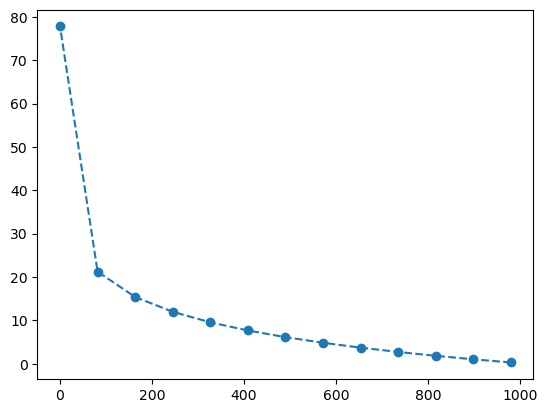

In [11]:
plt.scatter(temp_gosat.pressure_levels, h(temp_gosat.pressure_levels))
plt.plot(temp_gosat.pressure_levels, h(temp_gosat.pressure_levels),linestyle='--')

In [22]:
tccon=xr.open_dataset('/work/bb1170/RUN/b383736/data/TCCON/TCCON_data/pa20040602_20251122.public.qc.nc')

/tmp/ipykernel_3767477/1334847433.py:1: FutureWarning: In a future version, xarray will not decode the variable 'day' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  tccon=xr.open_dataset('/work/bb1170/RUN/b383736/data/TCCON/TCCON_data/pa20040602_20251122.public.qc.nc')
/tmp/ipykernel_3767477/1334847433.py:1: FutureWarning: In a future version, xarray will not decode the variable 'hour' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is

In [23]:
temp_tccon=tccon.isel(time=20)
temp_gosat=gosat.isel(sounding_dim=20)


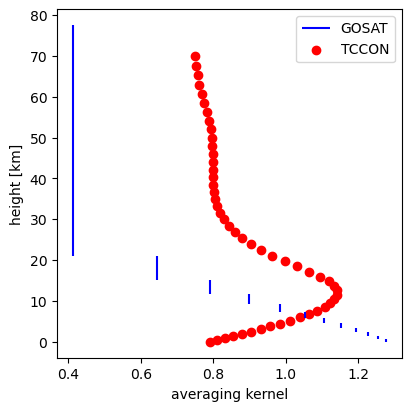

In [17]:
fig,ax = plt.subplots(1, 1, figsize=(4,  4), layout="constrained")
for k in range(len(temp_gosat.xco2_averaging_kernel)):
    if k==0:
        ax.vlines(x=temp_gosat.xco2_averaging_kernel[k],ymin=h(temp_gosat.pressure_levels[k],p0=temp_gosat.pressure_levels[0]),ymax=h(temp_gosat.pressure_levels[k+1],p0=temp_gosat.pressure_levels[0]), color='b', label='GOSAT')
    else:
        ax.vlines(x=temp_gosat.xco2_averaging_kernel[k],ymin=h(temp_gosat.pressure_levels[k],p0=temp_gosat.pressure_levels[0]),ymax=h(temp_gosat.pressure_levels[k+1],p0=temp_gosat.pressure_levels[0]), color='b')

ax.scatter(temp_tccon.ak_xco2,temp_tccon.ak_altitude, color='r', label='TCCON')
ax.set_xlabel('averaging kernel')
ax.set_ylabel('height [km]')
plt.legend()

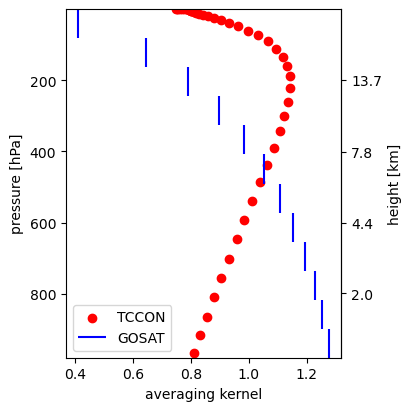

In [27]:
fig,ax = plt.subplots(1, 1, figsize=(4,  4), layout="constrained")
ax.scatter(temp_tccon.ak_xco2.values,temp_tccon.ak_pressure, color = 'r', label='TCCON')
for k in range(len(temp_gosat.xco2_averaging_kernel)):
    if k==0:
        ax.vlines(x=temp_gosat.xco2_averaging_kernel[k],ymin=temp_gosat.pressure_levels[k],ymax=temp_gosat.pressure_levels[k+1],color='b', label='GOSAT')
    else:
        ax.vlines(x=temp_gosat.xco2_averaging_kernel[k],ymin=temp_gosat.pressure_levels[k],ymax=temp_gosat.pressure_levels[k+1],color='b')
ax.yaxis.set_inverted(True)
ax.set_xlabel('averaging kernel')
ax.set_ylabel('pressure [hPa]')
ax.set_ylim(
    temp_gosat.pressure_levels.max(),
    temp_gosat.pressure_levels.min()
)
# Secondary y-axis
secax = ax.secondary_yaxis('right', functions=(h, p))
heights = np.round(h(np.array([800,600,400,200])),1)
secax.set_yticks(heights)
secax.set_ylabel("height [km]")
plt.legend(loc='lower left')
plt.savefig('figures_2/averaging_kernel_gosat_tccon/pressure_profile.png')

In [39]:
sum(temp_tccon.integration_operator*temp_tccon.ak_xco2.values/sum(temp_tccon.ak_xco2.values))

<xarray.DataArray 'integration_operator' ()> Size: 4B
array(0.02156833, dtype=float32)
Coordinates:
    time            datetime64[ns] 8B 2004-06-02T19:48:25.056000
    prior_altitude  float32 4B 70.0

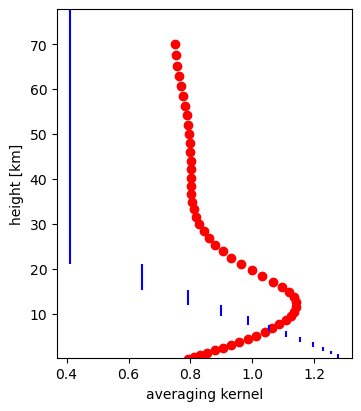

In [45]:
fig,ax = plt.subplots(1, 1, figsize=(3.5, 4), layout="constrained")
ax.scatter(temp_tccon.ak_xco2,temp_tccon.ak_altitude, color = 'r', label='TCCON')
for k in range(len(temp_gosat.xco2_averaging_kernel)):
    if k==0:
        ax.vlines(x=temp_gosat.xco2_averaging_kernel[k],ymin=h(temp_gosat.pressure_levels[k]),ymax=h(temp_gosat.pressure_levels[k+1]),color='b', label='GOSAT')
    else:
        ax.vlines(x=temp_gosat.xco2_averaging_kernel[k],ymin=h(temp_gosat.pressure_levels[k]),ymax=h(temp_gosat.pressure_levels[k+1]),color='b')
ax.yaxis.set_inverted(True)
ax.set_xlabel('averaging kernel')
ax.set_ylabel('height [km]')
ax.set_ylim(
    h(temp_gosat.pressure_levels.max()),
    h(temp_gosat.pressure_levels.min())
)

plt.savefig('figures_2/averaging_kernel_gosat_tccon/height_profile.png')

In [47]:
temp_gosat.pressure_levels

<xarray.DataArray 'pressure_levels' (level_dim: 13)> Size: 52B
array([9.801692e+02, 8.984968e+02, 8.168243e+02, 7.351519e+02, 6.534795e+02,
       5.718071e+02, 4.901346e+02, 4.084622e+02, 3.267897e+02, 2.451173e+02,
       1.634449e+02, 8.177243e+01, 1.000000e-01], dtype=float32)
Dimensions without coordinates: level_dim
Attributes:
    units:     hPa
    comments:  Pressure levels define the boundaries of the averaging kernel ...

<xarray.DataArray 'xco2_averaging_kernel' ()> Size: 4B
array(12.000002, dtype=float32)

# TM5-4DVar prior flux

In [2]:
prior=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_1x1_prior_cut.nc')

In [5]:
prior

<xarray.Dataset> Size: 22MB
Dimensions:         (latitude: 44, longitude: 72, time: 176)
Coordinates:
  * latitude        (latitude) float64 352B 12.5 13.5 14.5 ... 53.5 54.5 55.5
  * longitude       (longitude) float64 576B -133.5 -132.5 ... -63.5 -62.5
  * time            (time) datetime64[ns] 1kB 2009-01-01 ... 2023-08-01
Data variables:
    grid_cell_area  (latitude, longitude) float64 25kB ...
    CO2_flux_nee    (time, latitude, longitude) float64 4MB ...
    CO2_flux_fire   (time, latitude, longitude) float64 4MB ...
    CO2_flux_oce    (time, latitude, longitude) float64 4MB ...
    CO2_flux_fos    (time, latitude, longitude) float64 4MB ...
    total_flux      (time, latitude, longitude) float64 4MB ...

In [17]:
start_date=dt.date(2009,1,1)
end_date=dt.date(2023,8,1)

/tmp/ipykernel_2994244/3628273607.py:2: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  for date in pd.date_range(start_date, end_date, freq='Y'):
/tmp/ipykernel_2994244/3628273607.py:10: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  for date in pd.date_range(start_date, end_date, freq='Y'):
/tmp/ipykernel_2994244/3628273607.py:18: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  for date in pd.date_range(start_date, end_date, freq='Y'):
/tmp/ipykernel_2994244/3628273607.py:26: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  for date in pd.date_range(start_date, end_date, freq='Y'):


Text(0.5, 1.0, 'prior flux Fossile Fuel')

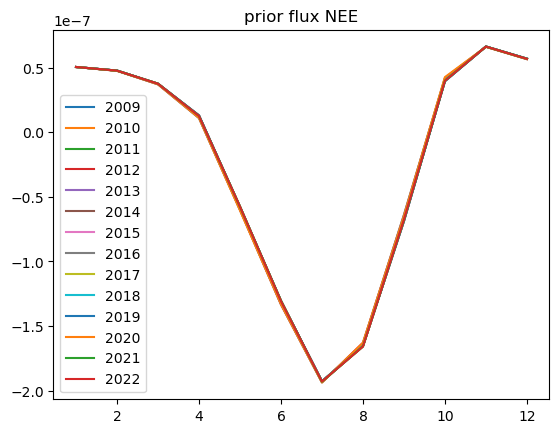

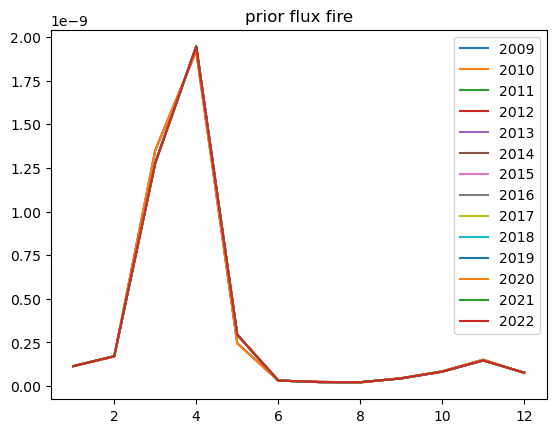

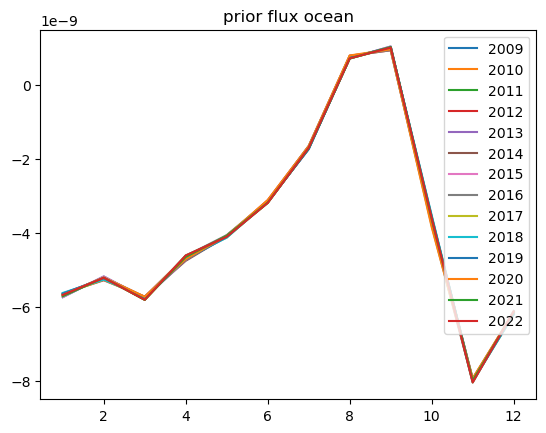

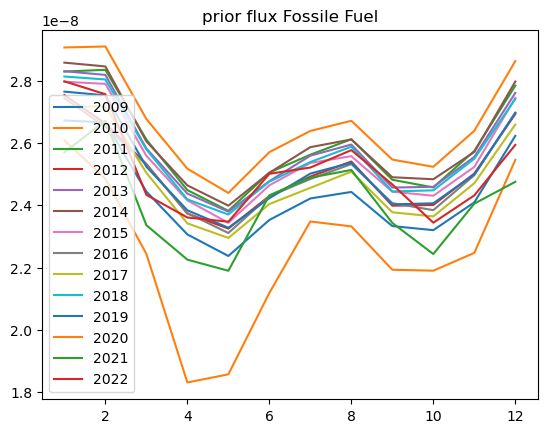

In [31]:
plt.figure()
for date in pd.date_range(start_date, end_date, freq='Y'):
    temp=prior.where(prior.time.dt.year==date.year,drop=True)
    temp=temp.sel(latitude=40.5).sel(longitude=-95.5)
    plt.plot(temp.time.dt.month, temp.CO2_flux_nee.values,label=f'{date.year}')
plt.legend()
plt.title('prior flux NEE')

plt.figure()
for date in pd.date_range(start_date, end_date, freq='Y'):
    temp=prior.where(prior.time.dt.year==date.year,drop=True)
    temp=temp.sel(latitude=40.5).sel(longitude=-95.5)
    plt.plot(temp.time.dt.month, temp.CO2_flux_fire.values,label=f'{date.year}')
plt.legend()
plt.title('prior flux fire')

plt.figure()
for date in pd.date_range(start_date, end_date, freq='Y'):
    temp=prior.where(prior.time.dt.year==date.year,drop=True)
    temp=temp.sel(latitude=45.5).sel(longitude=-132.5)
    plt.plot(temp.time.dt.month, temp.CO2_flux_oce.values,label=f'{date.year}')
plt.legend()
plt.title('prior flux ocean')

plt.figure()
for date in pd.date_range(start_date, end_date, freq='Y'):
    temp=prior.where(prior.time.dt.year==date.year,drop=True)
    temp=temp.sel(latitude=40.5).sel(longitude=-95.5)
    plt.plot(temp.time.dt.month, temp.CO2_flux_fos.values,label=f'{date.year}')
plt.legend()
plt.title('prior flux Fossile Fuel')

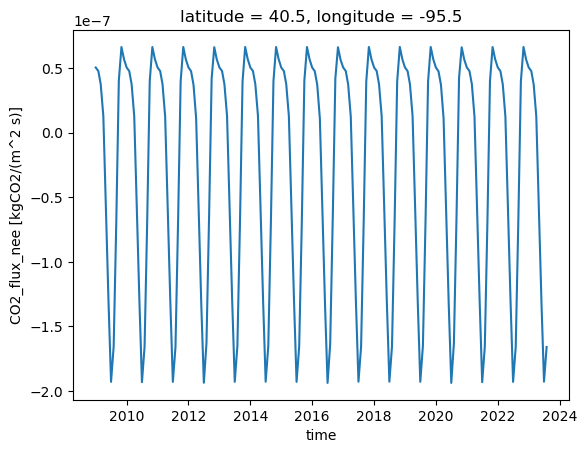

In [13]:
prior.sel(latitude=40.5).sel(longitude=-95.5).CO2_flux_nee.plot()

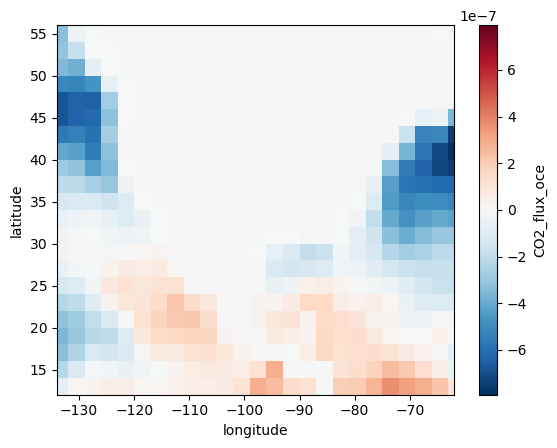

In [30]:
prior.CO2_flux_oce.sum('time').plot()

# Regions

In [2]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D

In [3]:
prior=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_1x1_prior.nc')
prior = prior.assign_coords(time=("months",[dt.datetime(year, month,1) for year, month in prior.month_tuple.values]), latitude=prior.latitude-89.5, longitude=prior.longitude-179.5).swap_dims({"months": "time"})
prior=prior.where((prior.time.dt.year==2020)|(prior.time.dt.year==2021)|(prior.time.dt.year==2020),drop=True)


In [4]:
prior['total_flux']=(prior.CO2_flux_nee+prior.CO2_flux_fire+prior.CO2_flux_oce+prior.CO2_flux_fos)*44/12*1e-3/(24*60*60)

In [5]:
analy_region_lat=[20,48]
analy_region_lon=[-126,-70]

# four_times_four 
res=2
n_regions=[2,3] #lat, lon
lat_dist=round((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)

In [7]:
regions_lat[1:-1]

[34]

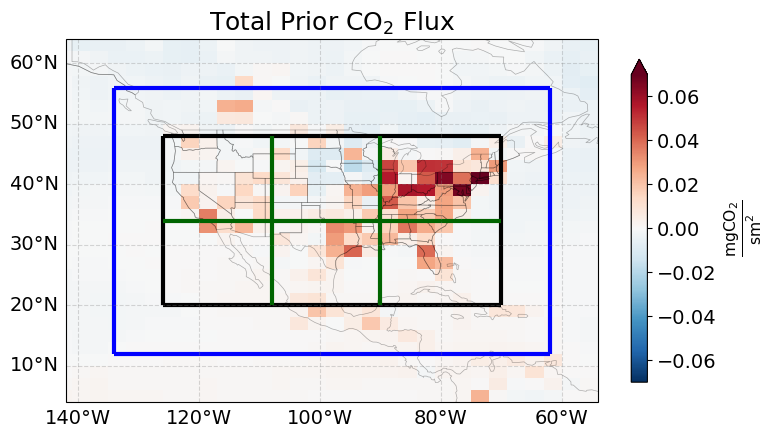

In [8]:
region_lat=[4,64]
region_lon=[-142,-54]
temp=prior.where((prior.latitude>=region_lat[0])&(prior.latitude<=region_lat[1])&(prior.longitude>=region_lon[0])&(prior.longitude<=region_lon[1]),drop=True)
fig,ax=plt.subplots(figsize=(8,5), subplot_kw={'projection': ccrs.PlateCarree()})

plot=(temp.mean('time').total_flux*1e6).plot(ax=ax, cmap='RdBu_r', vmin=-0.07, vmax=0.07,rasterized=True, cbar_kwargs={'location':'right','shrink':0.7})
plot.colorbar.ax.tick_params(labelsize=14)
plot.colorbar.set_label('$\\mathrm{\\frac{mgCO_2}{s m^2}}$', fontsize=16)

'''Flex_region_lat=[4,64]
Flex_region_lon=[-142,-54]
ax.hlines(Flex_region_lat[0],Flex_region_lon[0],Flex_region_lon[1],color='green')
ax.hlines(Flex_region_lat[1],Flex_region_lon[0],Flex_region_lon[1],color='green')
ax.vlines(Flex_region_lon[0],Flex_region_lat[0],Flex_region_lat[1],color='green')
ax.vlines(Flex_region_lon[1],Flex_region_lat[0],Flex_region_lat[1],color='green')'''

inv_region_lat=[12,56]
inv_region_lon=[-134,-62]
ax.hlines(inv_region_lat[0],inv_region_lon[0],inv_region_lon[1],color='blue',linewidths=3)
ax.hlines(inv_region_lat[1],inv_region_lon[0],inv_region_lon[1],color='blue',linewidths=3)
ax.vlines(inv_region_lon[0],inv_region_lat[0],inv_region_lat[1],color='blue',linewidths=3)
ax.vlines(inv_region_lon[1],inv_region_lat[0],inv_region_lat[1],color='blue',linewidths=3)

analy_region_lat=[20,48]
analy_region_lon=[-126,-70]
ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black',linewidths=3)
ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black',linewidths=3)
ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black',linewidths=3)
ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black',linewidths=3)

for lat in regions_lat[1:-1]:
    ax.hlines(lat,analy_region_lon[0],analy_region_lon[1],color='darkgreen',linewidths=3)
for lon in regions_lon[1:-1]:
    ax.vlines(lon,analy_region_lat[0],analy_region_lat[1],color='darkgreen',linewidths=3)


ax.set_xlabel('longitude')
ax.set_ylabel('latitude')
# Add coastlines
ax.coastlines(linewidth=0.5, alpha=0.3)
# Add U.S. state borders
ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 14}
gl.ylabel_style = {'size': 14}
ax.grid(c='lightgrey')
ax.set_xlim(region_lon[0],region_lon[1]) 
ax.set_ylim(region_lat[0],region_lat[1])
ax.tick_params(labelsize=20)
ax.set_aspect('equal')
ax.set_title('Total Prior CO$_2$ Flux',fontsize=18)
plt.tight_layout()
plt.savefig(f'figures_2/study_region.pdf',bbox_inches='tight',dpi=500)